# 03 — Feature Engineering & Selection
**Goal:** Engineer helpful time features, drop leaking/duplicate columns, and pick the best weather features for modeling (**no PCA needed**).

Steps:
1. Load clean splits from Notebook 02
2. Engineer cyclical hour features (`HOUR_SIN`, `HOUR_COS`)
3. Check duplicate & redundant columns
4. Rank feature importance (on Train only)
5. Save final `train.csv`, `val.csv`, `test.csv`


## 1. Load Clean Splits

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

sns.set_theme(style="whitegrid")

train = pd.read_csv("../data/processed/train_clean.csv", parse_dates=["DATE_TIME"])
val   = pd.read_csv("../data/processed/val_clean.csv",   parse_dates=["DATE_TIME"])
test  = pd.read_csv("../data/processed/test_clean.csv",  parse_dates=["DATE_TIME"])

print("Loaded:", train.shape, val.shape, test.shape)


Loaded: (53338, 29) (11968, 29) (11792, 29)


## 2. Feature Engineering (`HOUR_SIN`, `HOUR_COS`)
Wrap `HOUR` onto a 24-hour clock circle so the model sees smooth time-of-day curves.

In [2]:
for split in [train, val, test]:
    split["HOUR_SIN"] = np.sin(2 * np.pi * split["HOUR"] / 24)
    split["HOUR_COS"] = np.cos(2 * np.pi * split["HOUR"] / 24)

train[["DATE_TIME", "HOUR", "HOUR_SIN", "HOUR_COS", "TEMP_DIFF", "AC_POWER"]].head()


,DATE_TIME,HOUR,HOUR_SIN,HOUR_COS,TEMP_DIFF,AC_POWER
0,2020-05-15 05:45:00,5,0.965926,0.258819,-1.192519,0.0
1,2020-05-15 05:45:00,5,0.965926,0.258819,-0.954612,0.0
2,2020-05-15 05:45:00,5,0.965926,0.258819,-0.954612,0.0
3,2020-05-15 05:45:00,5,0.965926,0.258819,-0.954612,0.0
4,2020-05-15 05:45:00,5,0.965926,0.258819,-0.954612,0.0


## 3. Drop Leakage, Station IDs & Duplicate Columns
- **Target leakage:** `DC_POWER`, `DAILY_YIELD`, `TOTAL_YIELD` (these are outputs, not inputs)
- **Station / inverter IDs:** `PLANT_ID`, `SOURCE_KEY` (dropped from model inputs so the model generalizes to any station!)
- **100% duplicates:** `precipitation` (= `rain`) and `global_tilted_irradiance` (= `shortwave_radiation`)

In [3]:
# Confirm exact duplicates on Train
print("Corr(rain, precipitation):", round(train["rain"].corr(train["precipitation"]), 4))
print("Corr(shortwave_radiation, global_tilted_irradiance):", round(train["shortwave_radiation"].corr(train["global_tilted_irradiance"]), 4))


Corr(rain, precipitation): 1.0
Corr(shortwave_radiation, global_tilted_irradiance): 1.0


## 4. Feature Importance & Selection (Train Only)
Our validation check showed these **9 pure weather + time features** perform best (adding overlapping satellite weather columns added noise).

IRRADIATION             0.8983
TEMP_DIFF               0.0334
AMBIENT_TEMPERATURE     0.0234
wind_speed_10m          0.0143
relative_humidity_2m    0.0125
MODULE_TEMPERATURE      0.0068
HOUR_SIN                0.0053
cloud_cover             0.0044
HOUR_COS                0.0015
dtype: float64


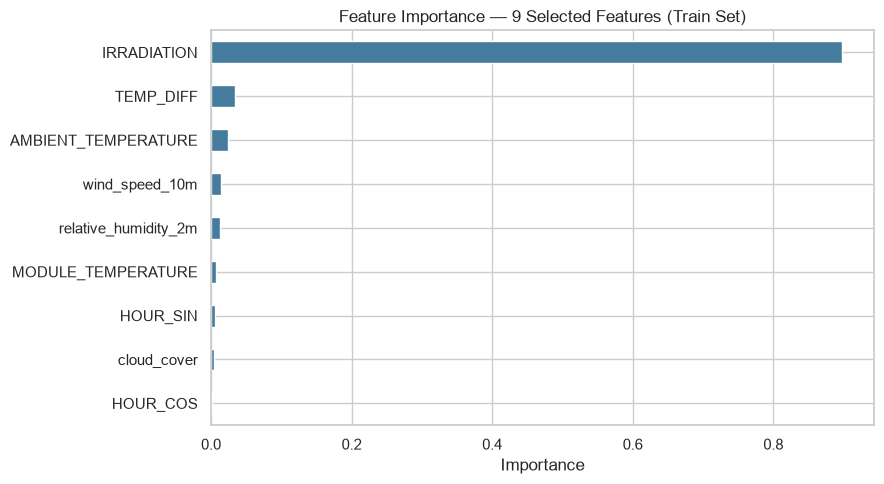

In [4]:
selected_features = [
    "IRRADIATION",
    "MODULE_TEMPERATURE",
    "AMBIENT_TEMPERATURE",
    "TEMP_DIFF",
    "relative_humidity_2m",
    "cloud_cover",
    "wind_speed_10m",
    "HOUR_SIN",
    "HOUR_COS",
]

rf = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(train[selected_features], train["AC_POWER"])

importance = pd.Series(rf.feature_importances_, index=selected_features).sort_values(ascending=False)
print(importance.round(4))

plt.figure(figsize=(9, 5))
importance.plot(kind="barh", color="#457b9d")
plt.title("Feature Importance — 9 Selected Features (Train Set)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 5. Save Final Modeling Datasets
We keep `DATE_TIME`, `PLANT_ID`, `SOURCE_KEY` **only as reference labels** for Loss Analysis later — they are NOT used as model inputs.

In [5]:
keep_cols = ["DATE_TIME", "PLANT_ID", "SOURCE_KEY"] + selected_features + ["AC_POWER"]

train[keep_cols].to_csv("../data/processed/train.csv", index=False)
val[keep_cols].to_csv("../data/processed/val.csv", index=False)
test[keep_cols].to_csv("../data/processed/test.csv", index=False)

print("Saved final modeling files:")
print("  train.csv:", train[keep_cols].shape)
print("  val.csv:  ", val[keep_cols].shape)
print("  test.csv: ", test[keep_cols].shape)


Saved final modeling files:
  train.csv: (53338, 13)
  val.csv:   (11968, 13)
  test.csv:  (11792, 13)
